# 02 · Analysis

Answers the six analysis questions with Spark's DataFrame API, using the Parquet tables
written by `01_data_preparation.ipynb`.

| # | Question | Tables |
|---|---|---|
| 1 | ¿Cómo evolucionó el dengue entre 2000 y 2025 y qué años fueron epidémicos? | `dengue_cases` |
| 2 | ¿Qué distritos tuvieron la mayor incidencia (casos por 100,000 habitantes) en 2022–2025? | `dengue_cases`, `population` |
| 3 | ¿Qué grupos de edad y qué sexo tienen la mayor incidencia? | `dengue_cases`, `population` |
| 4 | ¿La proporción de casos con signos de alarma o graves se relaciona con la cobertura de establecimientos de salud? | `dengue_cases`, `health_facilities`, `population` |
| 5 | ¿Los distritos en emergencia hídrica tuvieron mayor incidencia? ¿Influye la continuidad del servicio de agua? | `dengue_cases`, `population`, `water_emergencies` |
| 6 | ¿Cuántas semanas después de la lluvia aumentan los casos, y es distinto en la costa y en la selva? | `dengue_cases`, `weather_daily` |

Population is only available for 2022–2025, so every rate uses those years. Spark does all the
processing; matplotlib only draws results that Spark already aggregated (a few dozen rows). Each chart is
also saved to `docs/figures/` for the report.

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pyspark.sql import SparkSession, Window, functions as F

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "catalog.yaml").exists())
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder
         .master("local[*]")
         .appName("dengue-analysis")
         .config("spark.sql.session.timeZone", "America/Lima")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

cases, population, emergencies, facilities, weather = (
    spark.read.parquet(str(PROCESSED / name))
    for name in ["dengue_cases", "population", "water_emergencies", "health_facilities", "weather_daily"])

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/01 19:55:34 WARN Utils: Your hostname, Raymonds-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 192.168.18.58 instead (on interface en0)
26/11/01 19:55:34 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/01 19:55:34 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
# Chart style (reference palette): light surface, hairline grid on the value axis, muted axes.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

## Q1 · ¿Cómo evolucionó el dengue entre 2000 y 2025 y qué años fueron epidémicos?

Un año se considera **epidémico** cuando tiene más del doble del promedio de los cinco años anteriores. Esa
línea base es una ventana con un marco (`rowsBetween(-5, -1)`); `lag` da la variación respecto al año anterior.
La ventana no tiene partición, así que Spark mueve las filas a una sola partición: no es un problema aquí,
porque opera sobre 26 filas ya agregadas.

In [3]:
yearly = (cases.groupBy("year")
          .agg(F.count("*").alias("cases"),
               F.sum((F.col("severity") != "without_warning_signs").cast("int")).alias("warning_or_severe"),
               F.round(F.avg(F.col("is_confirmed").cast("int")) * 100, 1).alias("pct_confirmed")))

by_year = Window.orderBy("year")
yearly = (yearly
          .withColumn("pct_change", F.round((F.col("cases") / F.lag("cases").over(by_year) - 1) * 100, 1))
          .withColumn("baseline_5y", F.round(F.avg("cases").over(by_year.rowsBetween(-5, -1))))
          .withColumn("epidemic", F.coalesce(F.col("cases") > 2 * F.col("baseline_5y"), F.lit(False)))
          .orderBy("year"))
yearly.show(30)

+----+------+-----------------+-------------+----------+-----------+--------+
|year| cases|warning_or_severe|pct_confirmed|pct_change|baseline_5y|epidemic|
+----+------+-----------------+-------------+----------+-----------+--------+
|2000|  5557|                0|         16.1|      NULL|       NULL|   false|
|2001| 23526|              250|          6.1|     323.4|     5557.0|    true|
|2002|  8086|               15|         25.7|     -65.6|    14542.0|   false|
|2003|  3349|               15|         15.2|     -58.6|    12390.0|   false|
|2004|  9547|               34|         17.3|     185.1|    10130.0|   false|
|2005|  5640|               15|         43.4|     -40.9|    10013.0|   false|
|2006|  4022|                4|         30.3|     -28.7|    10030.0|   false|
|2007|  6344|               35|         43.6|      57.7|     6129.0|   false|
|2008| 12824|               35|         52.7|     102.1|     5780.0|    true|
|2009| 13407|               11|         99.9|       4.5|     767

In [4]:
epidemic_years = [row.year for row in yearly.filter(F.col("epidemic")).select("year").collect()]
by_epidemic_year = Window.partitionBy("year")

top_departments = (cases.filter(F.col("year").isin(epidemic_years))
                   .groupBy("year", "department").agg(F.count("*").alias("cases"))
                   .withColumn("pct_of_year", F.round(F.col("cases") / F.sum("cases").over(by_epidemic_year) * 100, 1))
                   .withColumn("rank", F.row_number().over(by_epidemic_year.orderBy(F.desc("cases"))))
                   .filter(F.col("rank") <= 3)
                   .orderBy("year", "rank"))
print("Epidemic years:", epidemic_years)
top_departments.show(30)

Epidemic years: [2001, 2008, 2011, 2017, 2023, 2024]


+----+-------------+-----+-----------+----+
|year|   department|cases|pct_of_year|rank|
+----+-------------+-----+-----------+----+
|2001|        PIURA|11713|       49.8|   1|
|2001|  LA LIBERTAD| 5718|       24.3|   2|
|2001|       TUMBES| 1803|        7.7|   3|
|2008|       LORETO| 7232|       56.4|   1|
|2008|        PIURA| 1702|       13.3|   2|
|2008|      UCAYALI|  931|        7.3|   3|
|2011|       LORETO|21245|       75.6|   1|
|2011|MADRE DE DIOS| 1956|        7.0|   2|
|2011|      UCAYALI| 1770|        6.3|   3|
|2017|        PIURA|44275|       64.8|   1|
|2017|  LA LIBERTAD| 5904|        8.6|   2|
|2017|          ICA| 4384|        6.4|   3|
|2023|        PIURA|79304|       30.9|   1|
|2023|   LAMBAYEQUE|31460|       12.3|   2|
|2023|         LIMA|30735|       12.0|   3|
|2024|         LIMA|87864|       32.4|   1|
|2024|  LA LIBERTAD|49931|       18.4|   2|
|2024|        PIURA|32246|       11.9|   3|
+----+-------------+-----+-----------+----+



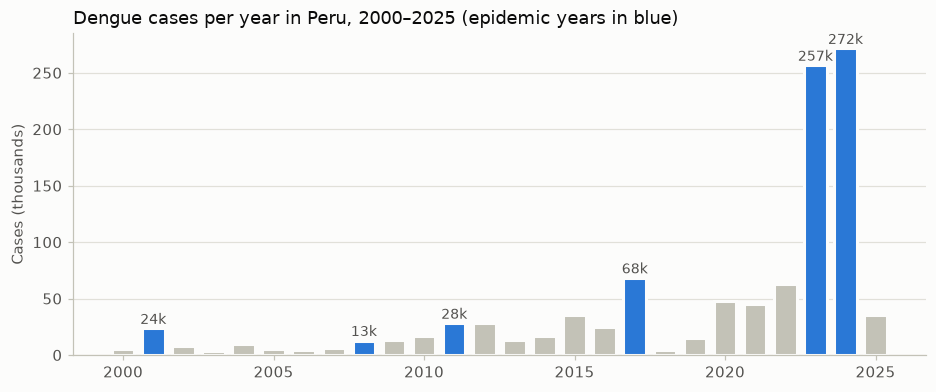

In [5]:
rows = yearly.select("year", "cases", "epidemic").collect()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar([r.year for r in rows], [r.cases / 1000 for r in rows], width=0.75,
       color=[BLUE if r.epidemic else AXIS for r in rows], edgecolor=SURFACE, linewidth=2)
for r in rows:
    if r.epidemic:
        ax.annotate(f"{r.cases / 1000:,.0f}k", (r.year, r.cases / 1000), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set_title("Dengue cases per year in Peru, 2000–2025 (epidemic years in blue)")
ax.set_ylabel("Cases (thousands)")
ax.set_xticks(range(2000, 2026, 5))
save(fig, "q1_cases_per_year")
plt.show()

**Respuesta.** El dengue pasó de 5,557 casos en 2000 a un récord de 271,531 en 2024 (unas 49 veces más). Seis años califican como epidémicos: **2001, 2008, 2011, 2017, 2023 y 2024**, con dos patrones:

- **Brotes costeros liderados por Piura**: 50% de los casos en 2001, 65% en 2017 y 31% en 2023.
- **Brotes amazónicos liderados por Loreto**: 56% de los casos en 2008 y 76% en 2011.

2023–2024 se distinguen por su escala y alcance: 528,172 casos en dos años, la mitad de todos los casos desde 2000, que se extendieron desde la costa norte hacia Lambayeque, La Libertad y Lima, que encabezó 2024 con 87,864 casos. En 2025 bajaron a 35,853 casos (−87%).

*Nota sobre los datos:* antes de 2009 la mayoría de los casos no tenía confirmación de laboratorio (6–53%), y los casos con signos de alarma solo aparecen desde 2011, cuando se empezó a usar la clasificación de la OMS de 2009. Las comparaciones de gravedad deberían empezar en 2011.

## Q2 · ¿Qué distritos tuvieron la mayor incidencia en 2022–2025?

Incidencia = casos por 100,000 habitantes, por distrito y año. Se excluyen los distritos con menos de 10,000
habitantes, porque ahí unos pocos casos producen tasas extremas e inestables.

**Tipo de join.** Los casos se agregan por distrito y año y luego se unen con la población mediante un
**LEFT JOIN**: la tabla de casos guía la consulta y ningún distrito con casos puede desaparecer. Antes de
confiar en él, un `left_anti` join confirma que todo distrito-año con casos tiene una fila de población.

El notebook 03 escribe esta misma consulta en Spark SQL y muestra que Catalyst convierte ambas versiones en
el mismo plan físico.

In [6]:
MIN_POPULATION = 10_000

district_cases = (cases.filter(F.col("year").between(2022, 2025))
                  .groupBy("year", "ubigeo").agg(F.count("*").alias("cases")))
district_population = (population
                       .groupBy("year", "ubigeo", "department", "province", "district")
                       .agg(F.sum("population").alias("population")))

missing = district_cases.join(district_population, ["year", "ubigeo"], "left_anti").count()
print("District-years with cases but no population:", missing)

top_districts = (district_cases
                    .join(district_population, ["year", "ubigeo"], "left")
                    .filter(F.col("population") >= MIN_POPULATION)
                    .withColumn("incidence_100k", F.round(F.col("cases") / F.col("population") * 100_000, 1))
                    .withColumn("rank", F.dense_rank().over(
                        Window.partitionBy("year").orderBy(F.desc(F.col("cases") / F.col("population")))))
                    .filter(F.col("rank") <= 5)
                    .select("year", "rank", "department", "province", "district", "cases", "population", "incidence_100k")
                    .orderBy("year", "rank"))
top_districts.show(20, truncate=False)

District-years with cases but no population: 0


+----+----+-----------+-----------------+--------------------+-----+----------+--------------+
|year|rank|department |province         |district            |cases|population|incidence_100k|
+----+----+-----------+-----------------+--------------------+-----+----------+--------------+
|2022|1   |ÁNCASH     |CASMA            |CASMA               |1927 |38179     |5047.3        |
|2022|2   |PIURA      |MORROPÓN         |MORROPÓN            |683  |14420     |4736.5        |
|2022|3   |AMAZONAS   |BAGUA            |BAGUA               |1342 |29254     |4587.4        |
|2022|4   |CUSCO      |LA CONVENCIÓN    |SANTA ANA           |1775 |41669     |4259.8        |
|2022|5   |JUNÍN      |CHANCHAMAYO      |SAN RAMÓN           |1110 |29710     |3736.1        |
|2023|1   |PIURA      |PAITA            |LA HUACA            |1890 |13958     |13540.6       |
|2023|2   |ÁNCASH     |SANTA            |NEPEÑA              |1428 |15854     |9007.2        |
|2023|3   |PIURA      |SULLANA          |MIGUEL CH

+----------+----------------+-----+--------------+--------------+
|department|district        |cases|avg_population|incidence_100k|
+----------+----------------+-----+--------------+--------------+
|PIURA     |LA HUACA        |2372 |14026.75      |4227.6        |
|ÁNCASH    |NEPEÑA          |2016 |15904.5       |3168.9        |
|ÁNCASH    |CASMA           |4911 |38887.0       |3157.2        |
|PIURA     |IGNACIO ESCUDERO|2699 |22637.0       |2980.7        |
|ÁNCASH    |HUARMEY         |3363 |29490.5       |2850.9        |
|PIURA     |SALITRAL        |1163 |10598.5       |2743.3        |
|TUMBES    |CORRALES        |2857 |26049.75      |2741.9        |
|CAJAMARCA |JAÉN            |12928|122594.0      |2636.3        |
|AMAZONAS  |BAGUA           |3069 |29917.25      |2564.6        |
|CUSCO     |SANTA ANA       |4299 |42013.0       |2558.1        |
|PIURA     |MORROPÓN        |1456 |14709.0       |2474.7        |
|PIURA     |CASTILLA        |17041|176109.25     |2419.1        |
|LORETO   

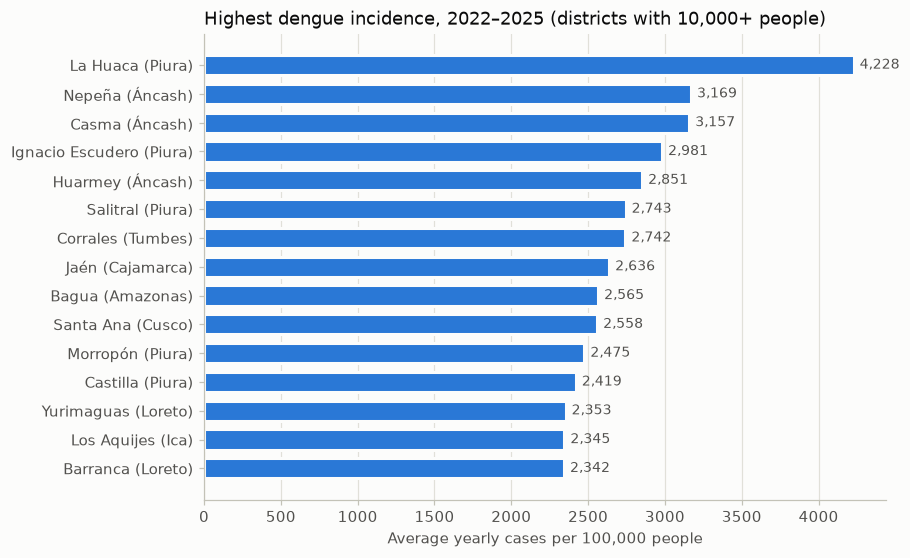

In [7]:
# Average yearly incidence over 2022-2025 (cases / person-years), for the chart
pooled = (district_cases.groupBy("ubigeo").agg(F.sum("cases").alias("cases"))
          .join(district_population.groupBy("ubigeo")
                .agg(F.max("department").alias("department"), F.max("district").alias("district"),
                     F.sum("population").alias("person_years"), F.avg("population").alias("avg_population")),
                "ubigeo", "left")
          .filter(F.col("avg_population") >= MIN_POPULATION)
          .withColumn("incidence_100k", F.round(F.col("cases") / F.col("person_years") * 100_000, 1))
          .orderBy(F.desc("incidence_100k")))
top15 = pooled.limit(15).collect()
pooled.select("department", "district", "cases", "avg_population", "incidence_100k").show(15, truncate=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
labels = [f"{r.district.title()} ({r.department.title()})" for r in reversed(top15)]
values = [r.incidence_100k for r in reversed(top15)]
ax.barh(labels, values, height=0.7, color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
for y, v in enumerate(values):
    ax.annotate(f"{v:,.0f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.set_title("Highest dengue incidence, 2022–2025 (districts with 10,000+ people)")
ax.set_xlabel("Average yearly cases per 100,000 people")
save(fig, "q2_top_districts")
plt.show()

**Respuesta.** Entre los distritos con 10,000 habitantes o más, la mayor incidencia anual promedio en 2022–2025 fue la de **La Huaca (Paita, Piura): 4,228 casos por 100,000 habitantes por año**. Solo en 2023 llegó a 13,541, alrededor de 1 de cada 7 residentes. Diez de los 15 primeros distritos están en la costa (5 en Piura, 3 en Áncash, 1 en Tumbes, 1 en Ica); el resto está del lado de la selva: Jaén, Bagua, Yurimaguas, Barranca y Santa Ana (Cusco).

El ranking anual sigue cada ola: Piura domina 2023; Áncash, La Libertad e Ica dominan 2024 (Huarmey: 8,162), y la selva (Loreto, San Martín, Cajamarca) domina 2025. Castilla (Piura) destaca por volumen, con 17,041 casos.

## Q3 · ¿Qué grupos de edad y qué sexo tienen la mayor incidencia?

Contar casos no basta: hay más adultos que niños, así que los adultos siempre tendrán más casos. La tasa
divide los casos entre las personas de cada grupo (sumadas en 2022–2025, es decir, personas-año).

**Tipo de join.** Ambos lados cubren la misma grilla completa (2 sexos × 5 etapas de vida), así que un
**INNER JOIN** no pierde nada y no requiere manejar nulos.

In [8]:
cases_by_group = (cases.filter(F.col("year").between(2022, 2025))
                  .groupBy("sex", "age_group").agg(F.count("*").alias("cases")))
population_by_group = population.groupBy("sex", "age_group").agg(F.sum("population").alias("person_years"))

rates = (cases_by_group.join(population_by_group, ["sex", "age_group"], "inner")
         .withColumn("pct_of_cases", F.round(F.col("cases") / F.sum("cases").over(Window.partitionBy()) * 100, 1))
         .withColumn("incidence_100k", F.round(F.col("cases") / F.col("person_years") * 100_000, 1))
         .orderBy("age_group", "sex"))
rates.show()

print("Incidence per 100,000 (rows: life stage, columns: sex)")
rates.groupBy("age_group").pivot("sex", ["F", "M"]).agg(F.first("incidence_100k")).orderBy("age_group").show()
(rates.groupBy("sex")
 .agg(F.round(F.sum("cases") / F.sum("person_years") * 100_000, 1).alias("incidence_100k"))
 .orderBy("sex").show())

+---+---------+------+------------+------------+--------------+
|sex|age_group| cases|person_years|pct_of_cases|incidence_100k|
+---+---------+------+------------+------------+--------------+
|  F|    00-11| 47707|    12802224|         7.6|         372.6|
|  M|    00-11| 51534|    13304133|         8.2|         387.4|
|  F|    12-17| 39375|     7134244|         6.3|         551.9|
|  M|    12-17| 44882|     7393723|         7.2|         607.0|
|  F|    18-29| 75334|    13294031|        12.0|         566.7|
|  M|    18-29| 61800|    13660719|         9.9|         452.4|
|  F|    30-59|141877|    27481464|        22.6|         516.3|
|  M|    30-59|101571|    27623393|        16.2|         367.7|
|  F|      60+| 35065|    10112381|         5.6|         346.8|
|  M|      60+| 28097|     9164910|         4.5|         306.6|
+---+---------+------+------------+------------+--------------+

Incidence per 100,000 (rows: life stage, columns: sex)


+---------+-----+-----+
|age_group|    F|    M|
+---------+-----+-----+
|    00-11|372.6|387.4|
|    12-17|551.9|607.0|
|    18-29|566.7|452.4|
|    30-59|516.3|367.7|
|      60+|346.8|306.6|
+---------+-----+-----+

+---+--------------+
|sex|incidence_100k|
+---+--------------+
|  F|         479.2|
|  M|         404.6|
+---+--------------+



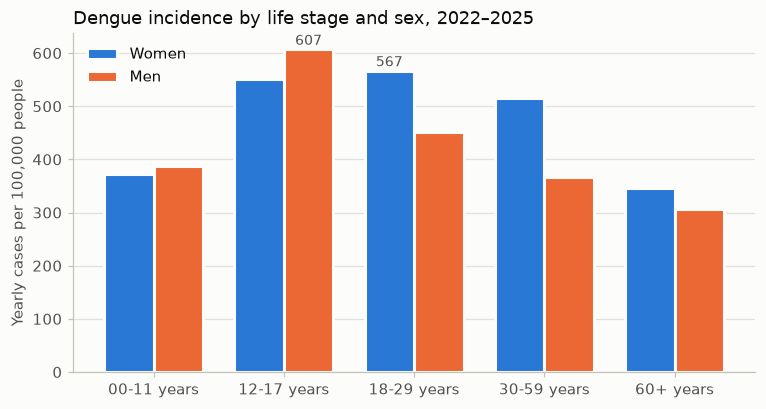

In [9]:
grid = {(r.age_group, r.sex): r.incidence_100k for r in rates.collect()}
groups = sorted({g for g, _ in grid})
width = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
for offset, (sex, label, color) in zip((-width / 2, width / 2), (("F", "Women", BLUE), ("M", "Men", ORANGE))):
    values = [grid[(g, sex)] for g in groups]
    ax.bar([i + offset for i in range(len(groups))], values, width=width, color=color, label=label,
           edgecolor=SURFACE, linewidth=2)
    peak = max(range(len(groups)), key=lambda i: values[i])
    ax.annotate(f"{values[peak]:,.0f}", (peak + offset, values[peak]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set_xticks(range(len(groups)), [f"{g} years" for g in groups])
ax.set_title("Dengue incidence by life stage and sex, 2022–2025")
ax.set_ylabel("Yearly cases per 100,000 people")
ax.legend(loc="upper left")
save(fig, "q3_age_sex")
plt.show()

**Respuesta.** Las mujeres tienen mayor incidencia que los hombres: **479 vs 405 casos por 100,000 por año (+18%)**. La diferencia viene de los adultos: 567 vs 452 entre 18 y 29 años, y 516 vs 368 entre 30 y 59 años (+40%). Entre niños y adolescentes los varones están ligeramente por encima, y la tasa más alta de todas está en los **adolescentes de 12 a 17 años** (varones 607, mujeres 552).

Los adultos de 30 a 59 años aportan la mayor cantidad de casos (39%) solo porque son el grupo más numeroso; su tasa no es la más alta. Por eso la pregunta se responde con tasas y no con conteos. Una explicación plausible, que estos datos no permiten comprobar, es la exposición en el hogar (donde pica el *Aedes aegypti*, durante el día) y las diferencias en quién busca atención y queda registrado.

## Q4 · ¿La proporción de casos con signos de alarma o graves se relaciona con la cobertura de establecimientos de salud?

Para cada distrito con al menos 30 casos en 2022–2025: la proporción de casos con signos de alarma o graves,
y los establecimientos de salud activos por 10,000 habitantes (población 2025). Los distritos se dividen en
cuatro grupos iguales según su cobertura con `ntile(4)`; "hospital" significa un establecimiento de nivel de
atención II o III.

**Tipo de join.** Los casos por distrito se unen con los establecimientos mediante un **LEFT JOIN**: un
distrito con dengue pero sin establecimientos activos debe quedarse en el análisis (con 0 establecimientos)
en lugar de desaparecer sin aviso.

In [10]:
MIN_CASES = 30

district_severity = (cases.filter(F.col("year").between(2022, 2025))
                     .groupBy("ubigeo")
                     .agg(F.count("*").alias("cases"),
                          F.sum((F.col("severity") != "without_warning_signs").cast("int")).alias("warning_or_severe"),
                          F.sum(F.col("is_confirmed").cast("int")).alias("confirmed")))
district_facilities = (facilities.groupBy("ubigeo")
                       .agg(F.count("*").alias("facilities"),
                            F.sum(F.col("care_level").isin("II", "III").cast("int")).alias("hospitals")))
population_2025 = (population.filter(F.col("year") == 2025)
                   .groupBy("ubigeo").agg(F.sum("population").alias("population")))

coverage = (district_severity
            .join(district_facilities, "ubigeo", "left")
            .join(population_2025, "ubigeo", "left")
            .fillna(0, subset=["facilities", "hospitals"])
            .filter((F.col("cases") >= MIN_CASES) & F.col("population").isNotNull())
            .withColumn("facilities_per_10k", F.col("facilities") / F.col("population") * 10_000)
            .withColumn("pct_warning_or_severe", F.col("warning_or_severe") / F.col("cases") * 100)
            .withColumn("coverage_quartile", F.ntile(4).over(Window.orderBy("facilities_per_10k"))))


def severity_summary(df, key):
    return (df.groupBy(key)
            .agg(F.count("*").alias("districts"),
                 F.round(F.min("facilities_per_10k"), 1).alias("min_per_10k"),
                 F.round(F.max("facilities_per_10k"), 1).alias("max_per_10k"),
                 F.sum("cases").alias("cases"),
                 F.round(F.sum("warning_or_severe") / F.sum("cases") * 100, 1).alias("pct_warning_or_severe"),
                 F.round(F.sum("confirmed") / F.sum("cases") * 100, 1).alias("pct_confirmed"))
            .orderBy(key))


by_quartile = severity_summary(coverage, "coverage_quartile")
by_quartile.show()
severity_summary(coverage.withColumn("has_hospital", F.col("hospitals") > 0), "has_hospital").show()
print("Pearson r across districts (facilities per 10k vs % warning or severe):",
      round(coverage.stat.corr("facilities_per_10k", "pct_warning_or_severe"), 3))

+-----------------+---------+-----------+-----------+------+---------------------+-------------+
|coverage_quartile|districts|min_per_10k|max_per_10k| cases|pct_warning_or_severe|pct_confirmed|
+-----------------+---------+-----------+-----------+------+---------------------+-------------+
|                1|      122|        0.0|        3.2|195507|                  9.6|         97.0|
|                2|      122|        3.2|        5.2|147697|                 11.6|         97.4|
|                3|      121|        5.3|        7.8|115730|                 11.6|         97.4|
|                4|      121|        7.9|       38.0|167264|                 13.0|         98.1|
+-----------------+---------+-----------+-----------+------+---------------------+-------------+



+------------+---------+-----------+-----------+------+---------------------+-------------+
|has_hospital|districts|min_per_10k|max_per_10k| cases|pct_warning_or_severe|pct_confirmed|
+------------+---------+-----------+-----------+------+---------------------+-------------+
|       false|      372|        0.0|       23.7|219231|                  9.8|         97.2|
|        true|      114|        1.2|       38.0|406967|                 12.2|         97.6|
+------------+---------+-----------+-----------+------+---------------------+-------------+



Pearson r across districts (facilities per 10k vs % warning or severe): 0.069


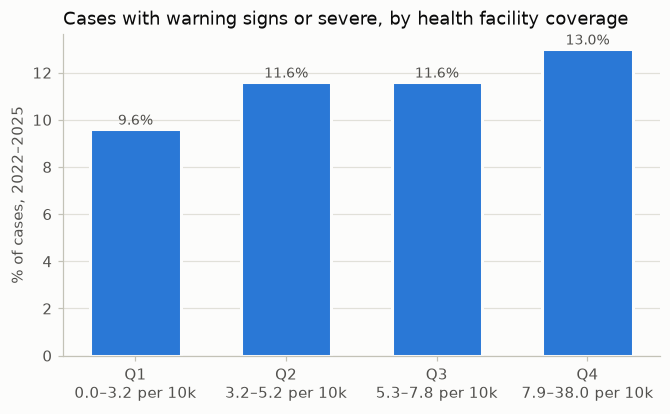

In [11]:
rows = by_quartile.collect()
fig, ax = plt.subplots(figsize=(7, 3.8))
x = range(len(rows))
ax.bar(x, [r.pct_warning_or_severe for r in rows], width=0.6, color=BLUE, edgecolor=SURFACE, linewidth=2)
for i, r in enumerate(rows):
    ax.annotate(f"{r.pct_warning_or_severe:.1f}%", (i, r.pct_warning_or_severe), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set_xticks(list(x), [f"Q{r.coverage_quartile}\n{r.min_per_10k}–{r.max_per_10k} per 10k" for r in rows])
ax.set_title("Cases with warning signs or severe, by health facility coverage")
ax.set_ylabel("% of cases, 2022–2025")
save(fig, "q4_severity_coverage")
plt.show()

**Respuesta.** No. La proporción de casos con signos de alarma o graves **no** aumenta donde hay menos establecimientos; si acaso, va en sentido contrario: de 9.6% en los distritos con menor cobertura (hasta 3.2 establecimientos por 10,000 habitantes) a 13.0% en los de mayor cobertura, y 12.2% en los distritos con hospital frente a 9.8% en los que no tienen. En los 486 distritos la correlación es prácticamente nula (r = 0.07).

La lectura más probable tiene que ver con la detección, no con la biología: reconocer los signos de alarma requiere seguimiento clínico y pruebas de laboratorio, que están más disponibles donde hay más establecimientos y de mayor nivel, así que la gravedad probablemente está subregistrada en los distritos con menos servicios. La confirmación por laboratorio es alta en todas partes (97–98%).

## Q5 · ¿Los distritos en emergencia hídrica tuvieron mayor incidencia?

Los decretos de la SUNASS cubren 2017, 2023 y 2024; la población existe desde 2022, así que la comparación
usa 2023 y 2024.

**Tipos de join.**
- Población **LEFT JOIN** casos: se conservan todos los distritos, incluidos los que tienen cero casos.
  Comparar solo los distritos con casos ocultaría dónde *no* apareció el dengue.
- Ese resultado **LEFT JOIN** indicadores de emergencia: los distritos sin ningún decreto se quedan, con la
  etiqueta `none`.
- Las emergencias se agregan a una fila por distrito y año **antes** del join. Un distrito aparece una vez por
  decreto y por prórroga, así que unir las filas originales multiplicaría sus casos. Un **LEFT SEMI JOIN**
  ("quedarse con los casos cuyo distrito tuvo un decreto") lo evita por diseño, como muestran los conteos
  de abajo.

In [12]:
YEARS = [2023, 2024]
cases_2324 = cases.filter(F.col("year").isin(YEARS)).select("year", "ubigeo")
rain_rows = (emergencies.filter((F.col("emergency_type") == "rain") & F.col("year").isin(YEARS))
             .select("year", "ubigeo"))

print("Cases 2023-2024 in districts under a rain emergency")
print(f"  inner join with raw decree rows: {cases_2324.join(rain_rows, ['year', 'ubigeo'], 'inner').count():>9,}  (inflated)")
print(f"  left semi join                 : {cases_2324.join(rain_rows, ['year', 'ubigeo'], 'left_semi').count():>9,}")
print(f"  all cases 2023-2024            : {cases_2324.count():>9,}")

Cases 2023-2024 in districts under a rain emergency
  inner join with raw decree rows: 1,539,044  (inflated)


  left semi join                 :   352,213
  all cases 2023-2024            :   528,172


In [13]:
district_year = (population.filter(F.col("year").isin(YEARS))
                 .groupBy("year", "ubigeo", "department").agg(F.sum("population").alias("population"))
                 .join(cases_2324.groupBy("year", "ubigeo").agg(F.count("*").alias("cases")), ["year", "ubigeo"], "left")
                 .fillna(0, subset=["cases"]))

flags = (emergencies.filter(F.col("year").isin(YEARS))
         .groupBy("year", "ubigeo")
         .agg(*[F.max((F.col("emergency_type") == kind).cast("int")).alias(kind) for kind in ("rain", "drought", "other")],
              F.avg("water_hours_per_day").alias("water_hours_per_day")))

emergency_districts = (district_year.join(flags, ["year", "ubigeo"], "left")
                       .withColumn("emergency", F.when((F.col("rain") == 1) & (F.col("drought") == 1), "rain and drought")
                                                 .when(F.col("rain") == 1, "rain")
                                                 .when(F.col("drought") == 1, "drought")
                                                 .when(F.col("other") == 1, "other")
                                                 .otherwise("none")))

# Departments with real transmission that year (1,000+ cases), to compare like with like
dengue_departments = (district_year.groupBy("year", "department").agg(F.sum("cases").alias("cases"))
                      .filter(F.col("cases") >= 1000).select("year", "department"))


def incidence_by(df, *keys):
    return (df.groupBy(*keys)
            .agg(F.count("*").alias("districts"),
                 F.sum("cases").alias("cases"),
                 F.round(F.sum("cases") / F.sum("population") * 100_000, 1).alias("incidence_100k"),
                 F.round(F.avg((F.col("cases") > 0).cast("int")) * 100, 1).alias("pct_districts_with_cases"))
            .orderBy(*keys))


print("All districts")
incidence_by(emergency_districts, "year", "emergency").show()
print("Only departments with 1,000+ cases that year")
in_dengue_departments = emergency_districts.join(dengue_departments, ["year", "department"], "left_semi")
by_emergency = incidence_by(in_dengue_departments, "year", "emergency")
by_emergency.show()

All districts


+----+----------------+---------+------+--------------+------------------------+
|year|       emergency|districts| cases|incidence_100k|pct_districts_with_cases|
+----+----------------+---------+------+--------------+------------------------+
|2023|         drought|      479|  4968|          80.2|                     6.1|
|2023|            none|      143| 20905|         447.8|                    89.5|
|2023|           other|        1|    46|          49.0|                   100.0|
|2023|            rain|      742|223188|        1037.6|                    48.4|
|2023|rain and drought|      526|  7534|         256.0|                     4.4|
|2024|            none|     1021|150040|         660.0|                    25.0|
|2024|            rain|      870|121491|         940.4|                    35.2|
+----+----------------+---------+------+--------------+------------------------+

Only departments with 1,000+ cases that year


+----+----------------+---------+------+--------------+------------------------+
|year|       emergency|districts| cases|incidence_100k|pct_districts_with_cases|
+----+----------------+---------+------+--------------+------------------------+
|2023|         drought|      241|  4853|         168.9|                    11.2|
|2023|            none|      139| 20753|         446.2|                    90.6|
|2023|           other|        1|    46|          49.0|                   100.0|
|2023|            rain|      716|223188|        1040.0|                    50.1|
|2023|rain and drought|      215|  6839|         578.0|                     6.0|
|2024|            none|      642|148283|         820.6|                    33.0|
|2024|            rain|      527|119950|        1168.6|                    52.4|
+----+----------------+---------+------+--------------+------------------------+



In [14]:
water = (in_dengue_departments.filter(F.col("water_hours_per_day").isNotNull())
         .withColumn("water_supply", F.when(F.col("water_hours_per_day") < 12, "1. under 12 h/day")
                                      .when(F.col("water_hours_per_day") < 24, "2. 12-23 h/day")
                                      .otherwise("3. 24 h/day")))
print("Districts under a decree, by hours of water supply per day (departments with 1,000+ cases)")
incidence_by(water, "water_supply").show(truncate=False)

Districts under a decree, by hours of water supply per day (departments with 1,000+ cases)


+-----------------+---------+------+--------------+------------------------+
|water_supply     |districts|cases |incidence_100k|pct_districts_with_cases|
+-----------------+---------+------+--------------+------------------------+
|1. under 12 h/day|511      |215126|1773.3        |67.7                    |
|2. 12-23 h/day   |1173     |139551|588.9         |27.5                    |
|3. 24 h/day      |10       |3     |22.1          |20.0                    |
+-----------------+---------+------+--------------+------------------------+



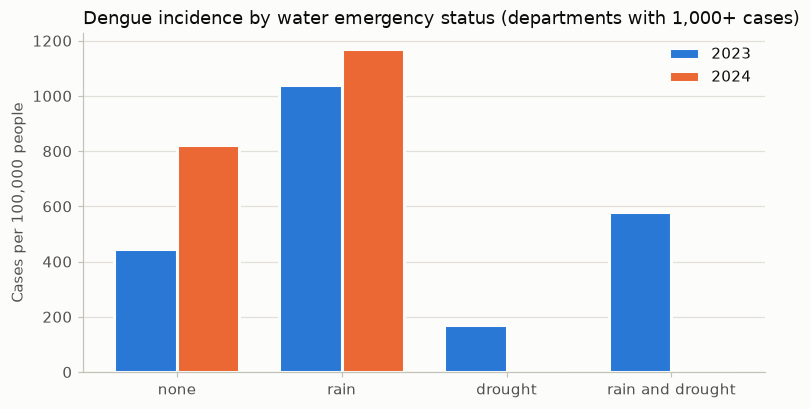

In [15]:
grid = {(r.year, r.emergency): r.incidence_100k for r in by_emergency.collect()}
groups = [g for g in ("none", "rain", "drought", "rain and drought") if any(k[1] == g for k in grid)]
width = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
for offset, year, color in ((-width / 2, 2023, BLUE), (width / 2, 2024, ORANGE)):
    ax.bar([i + offset for i in range(len(groups))], [grid.get((year, g), 0) for g in groups], width=width,
           color=color, label=str(year), edgecolor=SURFACE, linewidth=2)
ax.set_xticks(range(len(groups)), groups)
ax.set_title("Dengue incidence by water emergency status (departments with 1,000+ cases)")
ax.set_ylabel("Cases per 100,000 people")
ax.legend(loc="upper right")
save(fig, "q5_water_emergencies")
plt.show()

**Respuesta.** Sí, en el caso de las emergencias por lluvias. Dentro de los departamentos con transmisión real (1,000 casos o más ese año), los distritos en emergencia por lluvias tuvieron **1,040 casos por 100,000 en 2023 frente a 446** en los distritos sin ningún decreto (2.3 veces), y 1,169 frente a 821 en 2024 (1.4 veces). Los decretos por déficit hídrico muestran lo contrario (169 por 100,000 en 2023) porque se declararon sobre todo en departamentos andinos (Ayacucho, Cusco, Arequipa, Puno, Junín), donde el mosquito es poco frecuente. Todos los decretos de 2024 fueron por lluvias, así que los grupos de déficit hídrico solo existen para 2023.

La continuidad del servicio de agua muestra un gradiente marcado: los distritos con **menos de 12 horas de agua al día tuvieron 1,773 casos por 100,000 frente a 589** con 12–23 horas (3 veces). Esto es coherente con que el agua se almacene en recipientes donde se cría el *Aedes aegypti*. El grupo de 24 horas tiene solo 10 distritos y no es concluyente. Son asociaciones entre distritos, no efectos causales: las emergencias por lluvias y el suministro intermitente se concentran en la costa norte, que también tuvo la epidemia de 2023.

La verificación de joins muestra por qué importa el tipo de join: un inner join contra las filas originales de los decretos cuenta 1,539,044 casos, casi el triple de los 528,172 casos de 2023–2024, porque cada prórroga repite el distrito. El left semi join devuelve los 352,213 correctos.

## Q6 · ¿Cuántas semanas después de la lluvia aumentan los casos? Costa vs selva

Cada estación del SENAMHI se empareja con los casos de dengue de **su provincia**. La lluvia diaria se suma
por semana epidemiológica (una semana necesita al menos 5 días medidos). Para cada desfase (*lag*) de 0 a 12
semanas se calcula, por estación, la correlación entre la lluvia de la semana *t* y los casos de la semana
*t + desfase* (los casos se transforman con logaritmo porque los brotes abarcan varios órdenes de magnitud).

**Tipos de join.**
- Estaciones **CROSS JOIN** un calendario semanal: cada estación recibe todas las semanas, así una semana sin
  datos queda como un hueco en lugar de desplazar la serie de tiempo (`lead` cuenta filas, no fechas).
- Calendario **LEFT JOIN** lluvia semanal y casos semanales: las semanas sin casos son ceros reales y se
  mantienen.

El calendario semanal se construye con `spark.range`; `lead` sobre una ventana particionada por estación
construye las 13 columnas desfasadas en una sola pasada, y `unpivot` las convierte en filas.

In [16]:
COAST = ["105100", "104079", "103038"]  # Miraflores (Piura), Mallares (Sullana), Puerto Pizarro (Tumbes)
LAGS = list(range(13))

FIRST_WEEK, LAST_WEEK = date(2022, 1, 2), date(2025, 12, 28)  # Sundays starting epi weeks 2022-01 and 2025-52
calendar = (spark.range((LAST_WEEK - FIRST_WEEK).days // 7 + 1)
            .select(F.date_add(F.lit(FIRST_WEEK), (F.col("id") * 7).cast("int")).alias("week_start")))
stations = (weather.select("station_code", "station_name", "ubigeo").distinct()
            .withColumn("province_code", F.substring("ubigeo", 1, 4))
            .withColumn("region", F.when(F.col("station_code").isin(COAST), "coast").otherwise("jungle")))
weekly_rain = (weather
               .withColumn("week_start", F.date_sub("date", F.dayofweek("date") - 1))
               .groupBy("station_code", "week_start")
               .agg(F.sum("precip_mm").alias("rain_mm"), F.count("precip_mm").alias("days_measured")))
weekly_cases = (cases.withColumn("province_code", F.substring("ubigeo", 1, 4))
                .groupBy("province_code", "week_start").agg(F.count("*").alias("cases")))

station_weeks = (stations.crossJoin(calendar)
                 .join(weekly_rain, ["station_code", "week_start"], "left")
                 .join(weekly_cases, ["province_code", "week_start"], "left")
                 .withColumn("rain_mm", F.when(F.col("days_measured") >= 5, F.col("rain_mm")))
                 .fillna(0, subset=["cases"]))

(station_weeks.groupBy("region", "station_name", "province_code")
 .agg(F.count("*").alias("weeks"), F.count("rain_mm").alias("weeks_with_rain_data"),
      F.round(F.sum("rain_mm") / 4).alias("yearly_rain_mm"), F.sum("cases").alias("province_cases"),
      F.max("cases").alias("peak_week_cases"))
 .orderBy("region", F.desc("province_cases")).show(truncate=False))

+------+----------------+-------------+-----+--------------------+--------------+--------------+---------------+
|region|station_name    |province_code|weeks|weeks_with_rain_data|yearly_rain_mm|province_cases|peak_week_cases|
+------+----------------+-------------+-----+--------------------+--------------+--------------+---------------+
|coast |MIRAFLORES      |2001         |209  |186                 |195.0         |59806         |4720           |
|coast |MALLARES        |2006         |209  |184                 |174.0         |20244         |1892           |
|coast |PUERTO PIZARRO  |2401         |209  |187                 |467.0         |16436         |701            |
|jungle|PUCALLPA        |2501         |209  |204                 |1593.0        |11716         |541            |
|jungle|SHANUSI         |1602         |209  |208                 |2570.0        |11267         |377            |
|jungle|TARAPOTO        |2209         |209  |206                 |1392.0        |11163         |

In [17]:
by_week = Window.partitionBy("station_code").orderBy("week_start")
ids = ["station_code", "station_name", "region"]

lag_corr = (station_weeks
            .select(*ids, "rain_mm", *[(F.log1p("cases") if lag == 0 else F.lead(F.log1p("cases"), lag).over(by_week)).alias(str(lag))
                      for lag in LAGS])
            .groupBy(*ids)
            .agg(*[F.corr("rain_mm", str(lag)).alias(str(lag)) for lag in LAGS])
            .unpivot(ids, [str(lag) for lag in LAGS], "lag_weeks", "r")
            .withColumn("lag_weeks", F.col("lag_weeks").cast("int"))
            .cache())

best_lag = (lag_corr.withColumn("rank", F.row_number().over(Window.partitionBy("station_code").orderBy(F.desc("r"))))
            .filter(F.col("rank") == 1)
            .select("region", "station_name", "lag_weeks", F.round("r", 2).alias("r"))
            .orderBy("region", F.desc("r")))
best_lag.show(truncate=False)

print("Average correlation by region and lag")
(lag_corr.groupBy("region").pivot("lag_weeks", LAGS).agg(F.round(F.avg("r"), 2)).orderBy("region").show())

+------+----------------+---------+----+
|region|station_name    |lag_weeks|r   |
+------+----------------+---------+----+
|coast |MALLARES        |7        |0.44|
|coast |MIRAFLORES      |8        |0.38|
|coast |PUERTO PIZARRO  |10       |0.26|
|jungle|AMAZONAS        |0        |0.26|
|jungle|MOYOBAMBA       |5        |0.26|
|jungle|PUERTO MALDONADO|5        |0.22|
|jungle|TARAPOTO        |7        |0.21|
|jungle|PUCALLPA        |5        |0.16|
|jungle|SHANUSI         |1        |0.1 |
+------+----------------+---------+----+

Average correlation by region and lag


+------+----+----+----+----+----+----+----+----+----+----+----+----+----+
|region|   0|   1|   2|   3|   4|   5|   6|   7|   8|   9|  10|  11|  12|
+------+----+----+----+----+----+----+----+----+----+----+----+----+----+
| coast|0.19|0.21|0.24|0.27|0.29|0.31|0.33|0.35|0.35|0.35|0.35|0.33|0.31|
|jungle|0.17|0.17|0.17|0.15|0.16|0.17|0.15|0.14|0.12| 0.1|0.08|0.07|0.04|
+------+----+----+----+----+----+----+----+----+----+----+----+----+----+



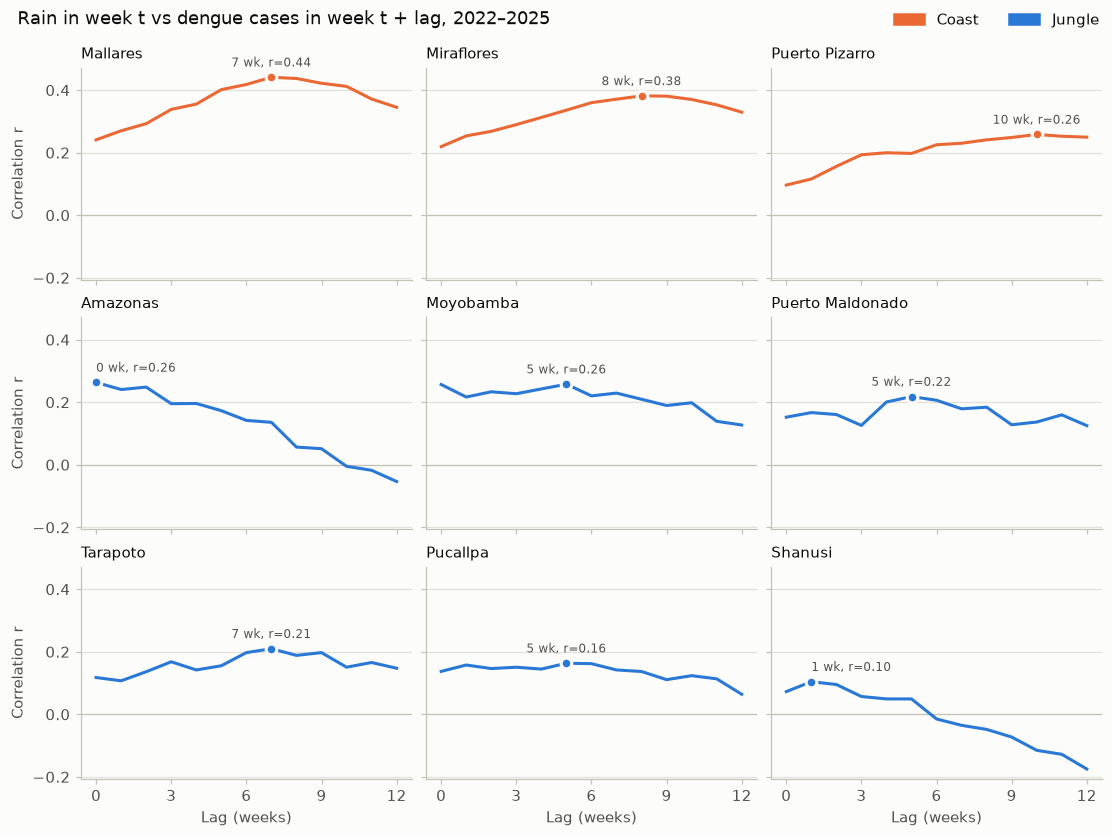

In [18]:
curves = {}
for r in lag_corr.orderBy("lag_weeks").collect():
    curves.setdefault((r.region, r.station_name), []).append(r.r)
order = sorted(curves, key=lambda k: (k[0], -max(curves[k])))

fig, axes = plt.subplots(3, 3, figsize=(10, 7.5), sharex=True, sharey=True, layout="constrained")
for ax, key in zip(axes.flat, order):
    region, name = key
    color = ORANGE if region == "coast" else BLUE
    values = curves[key]
    best = max(range(len(values)), key=lambda i: values[i])
    ax.axhline(0, color=AXIS, linewidth=0.8)
    ax.plot(LAGS, values, color=color, linewidth=2)
    ax.plot(best, values[best], "o", color=color, markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{best} wk, r={values[best]:.2f}", (best, values[best]), xytext=(0, 7), textcoords="offset points",
                ha="left" if best <= 1 else "right" if best >= 11 else "center", fontsize=8, color=INK_2)
    ax.set_title(name.title(), fontsize=10)
    ax.set_xticks([0, 3, 6, 9, 12])
for ax in axes[-1]:
    ax.set_xlabel("Lag (weeks)")
for ax in axes[:, 0]:
    ax.set_ylabel("Correlation r")
fig.legend(handles=[Patch(color=ORANGE, label="Coast"), Patch(color=BLUE, label="Jungle")],
           loc="outside upper right", ncol=2)
fig.suptitle("Rain in week t vs dengue cases in week t + lag, 2022–2025", x=0.01, ha="left", fontsize=12)
save(fig, "q6_rain_lag_by_station")
plt.show()

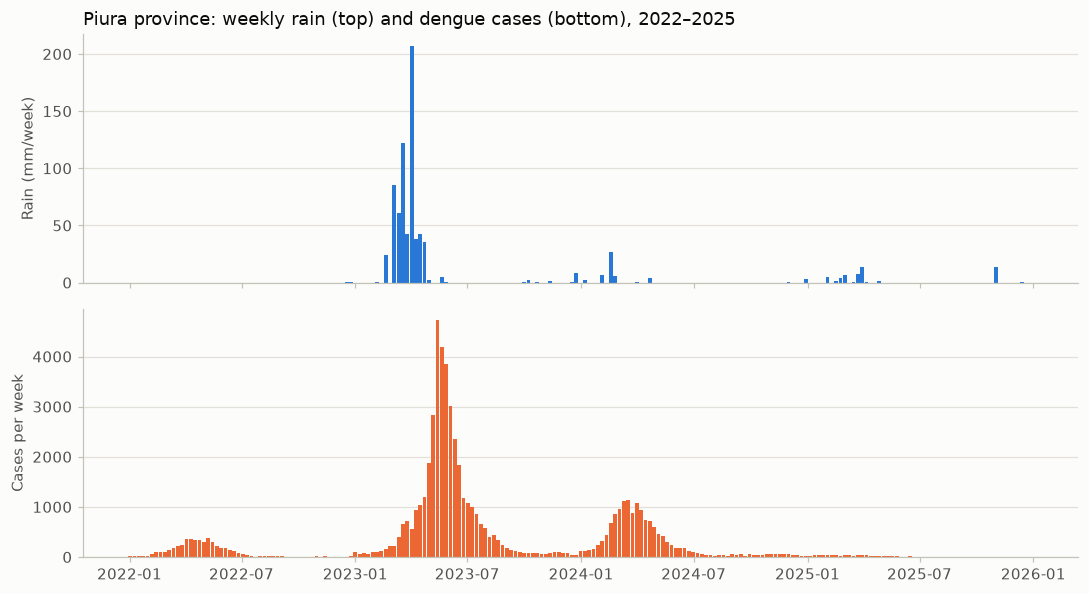

In [19]:
# Piura province: weekly rain (Miraflores station) and weekly cases, in two panels sharing the time axis
piura = (station_weeks.filter(F.col("station_code") == "105100")
         .select("week_start", "rain_mm", "cases").orderBy("week_start").collect())
weeks = [r.week_start for r in piura]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
top.bar(weeks, [r.rain_mm or 0 for r in piura], width=6, color=BLUE)
top.set_title("Piura province: weekly rain (top) and dengue cases (bottom), 2022–2025")
top.set_ylabel("Rain (mm/week)")
bottom.bar(weeks, [r.cases for r in piura], width=6, color=ORANGE)
bottom.set_ylabel("Cases per week")
fig.tight_layout()
save(fig, "q6_piura_weekly")
plt.show()

**Respuesta.** En la **costa, la lluvia antecede al aumento de casos en unos dos meses**. La correlación alcanza su máximo a las 7 semanas en Sullana (r = 0.44), a las 8 semanas en Piura (r = 0.38) y a las 10 semanas en Tumbes (r = 0.26), y el promedio costero se mantiene en r ≈ 0.35 entre las 7 y las 10 semanas. El gráfico de Piura lo muestra directamente: después de un 2022 seco, la semana más lluviosa fue la que empezó el 2 de abril de 2023 (207 mm), y los casos llegaron a su pico seis semanas después, en la semana del 14 de mayo (4,720 casos). El retraso es coherente con el tiempo que necesitan las poblaciones de mosquitos para crecer en los nuevos depósitos de agua estancada y con que la transmisión se amplifique a lo largo de varios ciclos mosquito-humano.

En la **selva la relación es débil y no tiene un desfase consistente**: r entre 0.10 y 0.26, mejores desfases de 0 a 7 semanas, y la correlación promedio baja a medida que crece el desfase. Allí llueven 1,300–2,600 mm al año, así que los criaderos nunca faltan y la lluvia no marca cuándo empiezan los brotes; otros factores (serotipos del virus, inmunidad de la población, campañas de control) deben explicar los cambios de un año a otro.

## Summary

| # | Question | Answer |
|---|---|---|
| 1 | Evolution and epidemic years | About 49 times more cases in 2024 than in 2000. Six epidemic years (2001, 2008, 2011, 2017, 2023, 2024): coastal ones led by Piura, Amazon ones led by Loreto. 2023–2024 hold half of all cases since 2000. |
| 2 | Highest incidence | La Huaca (Piura): 4,228 cases per 100,000 per year. 10 of the top 15 districts are coastal. |
| 3 | Age and sex | Women +18% over men, driven by adult women. Highest rate in adolescents aged 12–17. |
| 4 | Severity vs facilities | No sign that fewer facilities mean more severe cases (r = 0.07); the slight opposite trend points to under-detection. |
| 5 | Water emergencies | Rain emergencies: 1.4–2.3 times higher incidence. Under 12 h of water a day: 3 times higher than 12–23 h. |
| 6 | Rain → cases | Coast: cases follow rain by 7–10 weeks. Jungle: no consistent lag. |

**Spark operations used in this notebook**

- Transformations: `select`, `filter`, `withColumn`, `when`, `fillna`, `pivot`, `unpivot`.
- Joins: `left`, `inner`, `left_semi`, `left_anti`, `cross`, each one justified where it is used.
- Aggregations: `groupBy` + `agg` with `count`, `sum`, `avg`, `min`, `max`, `corr`, and `orderBy`.
- Window functions: `lag`, `lead`, a moving average with `rowsBetween`, `row_number`, `dense_rank`, `ntile`.

In [20]:
spark.stop()